In [6]:
import os

print("Current folder:", os.getcwd())
print("Available files:", os.listdir("."))

Current folder: C:\Users\VANSH\Desktop\Financial_Risk_Analytics
Available files: ['.ipynb_checkpoints', '.virtual_documents', '01_Data_Understanding.ipynb', 'data']


In [7]:
import os

print(os.listdir("data"))

['credit_risk_dataset.csv.csv']


In [9]:

import pandas as pd

df = pd.read_csv("data/credit_risk_dataset.csv.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [10]:

print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nLoan status distribution:")
print(df["loan_status"].value_counts())


Columns:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']

Missing values:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

Duplicate rows: 165

Loan status distribution:
loan_status
0    25473
1     7108
Name: count, dtype: int64


In [11]:

# Original dataset ko safe rakho
df_clean = df.copy()

print("Original shape:", df.shape)
print("Working copy shape:", df_clean.shape)


Original shape: (32581, 12)
Working copy shape: (32581, 12)


In [12]:

# Duplicate rows count before cleaning
print("Duplicates before:", df_clean.duplicated().sum())

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

print("Duplicates after:", df_clean.duplicated().sum())
print("Shape after removing duplicates:", df_clean.shape)


Duplicates before: 165
Duplicates after: 0
Shape after removing duplicates: (32416, 12)


In [13]:

# Employment length: fill with median
df_clean["person_emp_length"] = (
    df_clean["person_emp_length"].fillna(
        df_clean["person_emp_length"].median()
    )
)

# Interest rate: first use median for the same loan grade
grade_median = df_clean.groupby("loan_grade")[
    "loan_int_rate"
].transform("median")

df_clean["loan_int_rate"] = df_clean["loan_int_rate"].fillna(
    grade_median
)

# Any remaining missing interest rates: overall median
df_clean["loan_int_rate"] = df_clean["loan_int_rate"].fillna(
    df_clean["loan_int_rate"].median()
)

print("Missing values after cleaning:")
print(df_clean.isnull().sum())


Missing values after cleaning:
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64


In [14]:

print("Final shape:", df_clean.shape)
print("Total missing values:", df_clean.isnull().sum().sum())
print("Total duplicate rows:", df_clean.duplicated().sum())

df_clean.head()


Final shape: (32416, 12)
Total missing values: 0
Total duplicate rows: 0


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [15]:

total_loans = len(df_clean)

default_loans = (df_clean["loan_status"] == 1).sum()

default_rate = (default_loans / total_loans) * 100

print("Total loans:", total_loans)
print("Default loans:", default_loans)
print("Default rate:", round(default_rate, 2), "%")


Total loans: 32416
Default loans: 7089
Default rate: 21.87 %


In [16]:

print("Missing values:", df_clean.isnull().sum().sum())

print("\nAge summary:")
print(df_clean["person_age"].describe())

print("\nEmployment length summary:")
print(df_clean["person_emp_length"].describe())

print("\nAge above 100:")
print(df_clean[df_clean["person_age"] > 100][
    ["person_age", "person_emp_length"]
])


Missing values: 0

Age summary:
count    32416.000000
mean        27.747008
std          6.354100
min         20.000000
25%         23.000000
50%         26.000000
75%         30.000000
max        144.000000
Name: person_age, dtype: float64

Employment length summary:
count    32416.000000
mean         4.768880
std          4.090411
min          0.000000
25%          2.000000
50%          4.000000
75%          7.000000
max        123.000000
Name: person_emp_length, dtype: float64

Age above 100:
       person_age  person_emp_length
81            144                4.0
183           144                4.0
575           123                2.0
747           123                7.0
32297         144               12.0


In [17]:

grade_analysis = (
    df_clean.groupby("loan_grade")
    .agg(
        total_loans=("loan_status", "count"),
        default_loans=("loan_status", "sum"),
        avg_loan_amount=("loan_amnt", "mean")
    )
    .reset_index()
)

grade_analysis["default_rate_pct"] = (
    grade_analysis["default_loans"]
    / grade_analysis["total_loans"] * 100
).round(2)

grade_analysis = grade_analysis.sort_values(
    "default_rate_pct", ascending=False
)

grade_analysis


,loan_grade,total_loans,default_loans,avg_loan_amount,default_rate_pct
6,G,64,63,17195.703125,98.44
5,F,241,170,14717.323651,70.54
4,E,963,621,12919.911734,64.49
3,D,3620,2138,10855.759669,59.06
2,C,6438,1336,9219.175210,20.75
1,B,10387,1695,9992.228266,16.32
0,A,10703,1066,8545.702140,9.96


In [18]:

purpose_analysis = (
    df_clean.groupby("loan_intent")
    .agg(
        total_loans=("loan_status", "count"),
        default_loans=("loan_status", "sum"),
        avg_loan_amount=("loan_amnt", "mean")
    )
    .reset_index()
)

purpose_analysis["default_rate_pct"] = (
    purpose_analysis["default_loans"]
    / purpose_analysis["total_loans"] * 100
).round(2)

purpose_analysis = purpose_analysis.sort_values(
    "default_rate_pct", ascending=False
)

purpose_analysis


,loan_intent,total_loans,default_loans,avg_loan_amount,default_rate_pct
0,DEBTCONSOLIDATION,5189,1488,9605.270765,28.68
3,MEDICAL,6042,1617,9271.578120,26.76
2,HOMEIMPROVEMENT,3594,940,10362.124374,26.15
4,PERSONAL,5498,1094,9579.683521,19.90
1,EDUCATION,6411,1106,9480.049914,17.25
5,VENTURE,5682,844,9582.242168,14.85


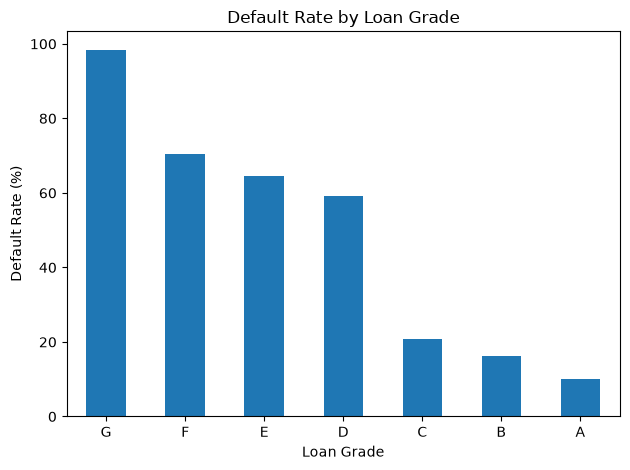

In [19]:

import matplotlib.pyplot as plt

grade_analysis.plot(
    x="loan_grade",
    y="default_rate_pct",
    kind="bar",
    legend=False
)

plt.title("Default Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [20]:

home_analysis = (
    df_clean.groupby("person_home_ownership")
    .agg(
        total_loans=("loan_status", "count"),
        default_loans=("loan_status", "sum"),
        avg_income=("person_income", "mean")
    )
    .reset_index()
)

home_analysis["default_rate_pct"] = (
    home_analysis["default_loans"]
    / home_analysis["total_loans"] * 100
).round(2)

home_analysis.sort_values(
    "default_rate_pct", ascending=False
)


,person_home_ownership,total_loans,default_loans,avg_income,default_rate_pct
3,RENT,16378,5177,55019.630663,31.61
1,OTHER,106,33,76561.273585,31.13
0,MORTGAGE,13369,1687,81150.979580,12.62
2,OWN,2563,192,57858.828326,7.49


In [21]:

df_clean["income_group"] = pd.cut(
    df_clean["person_income"],
    bins=[0, 25000, 50000, 75000, 100000, float("inf")],
    labels=[
        "Under 25K",
        "25K-50K",
        "50K-75K",
        "75K-100K",
        "Above 100K"
    ]
)

income_analysis = (
    df_clean.groupby("income_group", observed=False)
    .agg(
        total_loans=("loan_status", "count"),
        default_loans=("loan_status", "sum"),
        avg_loan_amount=("loan_amnt", "mean")
    )
    .reset_index()
)

income_analysis["default_rate_pct"] = (
    income_analysis["default_loans"]
    / income_analysis["total_loans"].replace(0, float("nan"))
    * 100
).round(2)

income_analysis


,income_group,total_loans,default_loans,avg_loan_amount,default_rate_pct
0,Under 25K,2450,1283,4662.285714,52.37
1,25K-50K,11549,3203,7676.441683,27.73
2,50K-75K,9585,1691,10013.445488,17.64
3,75K-100K,4641,512,11881.577246,11.03
4,Above 100K,4191,400,14267.477929,9.54


In [25]:

df_clean.to_csv(
    "data/credit_risk_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [26]:

import os

print(os.path.exists("data/credit_risk_cleaned.csv"))
print(os.listdir("data"))


True
['credit_risk_cleaned.csv', 'credit_risk_dataset.csv.csv']


In [27]:
home_analysis = (
    df_clean.groupby("person_home_ownership")
    .agg(
        total_loans=("loan_status", "count"),
        default_loans=("loan_status", "sum"),
        avg_income=("person_income", "mean")
    )
    .reset_index()
)

home_analysis["default_rate_pct"] = (
    home_analysis["default_loans"]
    / home_analysis["total_loans"] * 100
).round(2)

home_analysis.sort_values(
    "default_rate_pct", ascending=False
)

,person_home_ownership,total_loans,default_loans,avg_income,default_rate_pct
3,RENT,16378,5177,55019.630663,31.61
1,OTHER,106,33,76561.273585,31.13
0,MORTGAGE,13369,1687,81150.979580,12.62
2,OWN,2563,192,57858.828326,7.49


In [28]:
import pandas as pd

df_clean["income_group"] = pd.cut(
    df_clean["person_income"],
    bins=[0, 25000, 50000, 75000, 100000, float("inf")],
    labels=[
        "Under 25K",
        "25K-50K",
        "50K-75K",
        "75K-100K",
        "Above 100K"
    ]
)

income_analysis = (
    df_clean.groupby("income_group", observed=False)
    .agg(
        total_loans=("loan_status", "count"),
        default_loans=("loan_status", "sum"),
        avg_loan_amount=("loan_amnt", "mean")
    )
    .reset_index()
)

income_analysis["default_rate_pct"] = (
    income_analysis["default_loans"]
    / income_analysis["total_loans"].replace(0, float("nan"))
    * 100
).round(2)

income_analysis

,income_group,total_loans,default_loans,avg_loan_amount,default_rate_pct
0,Under 25K,2450,1283,4662.285714,52.37
1,25K-50K,11549,3203,7676.441683,27.73
2,50K-75K,9585,1691,10013.445488,17.64
3,75K-100K,4641,512,11881.577246,11.03
4,Above 100K,4191,400,14267.477929,9.54


In [29]:
df_clean.to_csv("data/credit_risk_cleaned.csv", index=False)
print("Updated dataset saved!")

Updated dataset saved!


In [30]:
df_clean.to_csv("data/credit_risk_cleaned.csv", index=False)

print("Updated dataset saved successfully!")
print("Final shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

Updated dataset saved successfully!
Final shape: (32416, 13)
Missing values: 0
Duplicate rows: 0


In [31]:
import os
import pandas as pd

file_path = "data/credit_risk_cleaned.csv"

print("File exists:", os.path.exists(file_path))

df_sql = pd.read_csv(file_path)

print("Dataset shape:", df_sql.shape)
print(df_sql.columns.tolist())
df_sql.head()

File exists: True
Dataset shape: (32416, 13)
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length', 'income_group']


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,income_group
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3,50K-75K
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2,Under 25K
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3,Under 25K
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2,50K-75K
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4,50K-75K
